In [ ]:
!pip install numpy matplotlib


In [ ]:
d_E = r * dphi_E              # deslocamento da roda esquerda
d_D = r * dphi_D              # deslocamento da roda direita
ds     = (d_D + d_E) / 2      # deslocamento do centro do robô
dtheta = (d_D - d_E) / L      # variação de orientação

x     = x + ds * cos(theta + dtheta/2)
y     = y + ds * sin(theta + dtheta/2)
theta = theta + dtheta


In [3]:
# lab2_utils.py
import math
import numpy as np

def normaliza_angulo(a):
    """Leva o ângulo para o intervalo (-pi, pi]."""
    return math.atan2(math.sin(a), math.cos(a))

def atualiza_odometria(x, y, theta, dphi_e, dphi_d, r, L):
    """Integra um passo de odometria. Retorna a nova pose (x, y, theta)."""
    d_e = r * dphi_e
    d_d = r * dphi_d
    ds = (d_d + d_e) / 2
    dtheta = (d_d - d_e) / L
    x += ds * math.cos(theta + dtheta / 2)
    y += ds * math.sin(theta + dtheta / 2)
    theta = normaliza_angulo(theta + dtheta)
    return x, y, theta

def scan_para_mundo(ranges, angle_min, angle_increment, pose,
                    range_min=0.12, range_max=3.5, passo=1):
    """Converte um scan em pontos (N x 2) no referencial global.
    - descarte leituras inválidas (inf, nan, fora de [range_min, range_max])
    - use apenas 1 a cada 'passo' feixes
    - pose = (x, y, theta) do robô no mundo
    """
    indices = np.arange(len(ranges))[::passo]
    distancias = np.asarray(ranges, dtype=float)[::passo]
    validos = (np.isfinite(distancias)
               & (distancias >= range_min)
               & (distancias <= range_max))
    distancias = distancias[validos]
    angulos = angle_min + indices[validos] * angle_increment
    x, y, theta = pose
    return np.column_stack((x + distancias * np.cos(theta + angulos),
                            y + distancias * np.sin(theta + angulos)))


In [4]:
from lab2_utils import *

# Valores FICTÍCIOS, usados só nos testes (os reais serão medidos em sala)
R, L = 0.05, 0.20

# Teste 1: ambas as rodas giram 1 rad -> robô anda em linha reta R*1
x, y, t = atualiza_odometria(0, 0, 0, 1.0, 1.0, R, L)
assert abs(x - R) < 1e-6 and abs(y) < 1e-6 and abs(t) < 1e-6

# Teste 2: rodas em sentidos opostos -> gira sem sair do lugar
x, y, t = atualiza_odometria(0, 0, 0, -1.0, 1.0, R, L)
assert abs(x) < 1e-6 and abs(y) < 1e-6
assert abs(t - 2 * R / L) < 1e-6

# Teste 3: robô em (1, 0) virado para +y; feixe frontal de 1 m
# deve atingir o ponto (1, 1) no mundo
pts = scan_para_mundo([1.0], 0.0, 0.01, (1.0, 0.0, math.pi/2))
assert pts.shape == (1, 2)
assert abs(pts[0, 0] - 1.0) < 1e-6 and abs(pts[0, 1] - 1.0) < 1e-6

# Teste 4: leituras inválidas devem ser descartadas
pts = scan_para_mundo([float('inf'), 0.0, 1.0], 0.0, 0.1, (0, 0, 0))
assert pts.shape == (1, 2)

print('Todos os testes passaram!')


Todos os testes passaram!


In [5]:
import time, math, threading
import numpy as np
import matplotlib.pyplot as plt
import roslibpy
from lab2_utils import *

ROBOT_IP = '192.168.0.135'         # <-- IP do seu robô
NS = ''                            # prefixo dos tópicos, ex: '/tb03' (só se o professor indicar)

# Parâmetros geométricos: MEDIDOS por vocês na seção 2.2.1 (em metros)
R_RODA = 0.0   # <-- raio da roda medido
L_EIXO = 0.0   # <-- distância entre as rodas medida
# assert R_RODA > 0 and L_EIXO > 0, 'Preencha R_RODA e L_EIXO com os valores medidos!'

client = roslibpy.Ros(host=ROBOT_IP, port=9090)
client.run()
print('Conectado:', client.is_connected)

Conectado: True


In [6]:
import time, math, threading
import numpy as np
import matplotlib.pyplot as plt
import roslibpy
from lab2_utils import *

ROBOT_IP = '192.168.0.135'         # <-- IP do seu robô
NS = ''                            # prefixo dos tópicos, ex: '/tb03' (só se o professor indicar)

# Parâmetros geométricos: MEDIDOS por vocês na seção 2.2.1 (em metros)
R_RODA = 0.03   # <-- raio da roda medido
L_EIXO = 0.28  # <-- distância entre as rodas medida
assert R_RODA > 0 and L_EIXO > 0, 'Preencha R_RODA e L_EIXO com os valores medidos!'

client = roslibpy.Ros(host=ROBOT_IP, port=9090)
client.run()
print('Conectado:', client.is_connected)

# --- estado compartilhado entre os callbacks ---
phi_prev   = [None]          # última leitura das rodas (esq, dir)
pose_prop = [0.0, 0.0, 0.0] # sua odometria (x, y, theta)
traj_prop = []               # histórico da sua odometria
traj_odom = []               # histórico de /odom: (x, y)
ultimo_scan = [None]

def cb_joint(msg):
    i_e = msg['name'].index('wheel_left_joint')
    i_d = msg['name'].index('wheel_right_joint')
    phi_e, phi_d = msg['position'][i_e], msg['position'][i_d]
    if phi_prev[0] is not None:
        dphi_e = phi_e - phi_prev[0][0]
        dphi_d = phi_d - phi_prev[0][1]
        x, y, th = pose_prop
        pose_prop[:] = atualiza_odometria(x, y, th, dphi_e, dphi_d, R_RODA, L_EIXO)
        traj_prop.append(tuple(pose_prop))
    phi_prev[0] = (phi_e, phi_d)

def cb_odom(msg):
    p = msg['pose']['pose']['position']
    traj_odom.append((p['x'], p['y']))            # usaremos apenas a posição

def cb_scan(msg):
    ultimo_scan[0] = msg

t_joint = roslibpy.Topic(client, NS + '/joint_states', 'sensor_msgs/JointState')
t_odom = roslibpy.Topic(client, NS + '/odom', 'nav_msgs/Odometry')
t_scan = roslibpy.Topic(client, NS + '/scan', 'sensor_msgs/LaserScan')
t_joint.subscribe(cb_joint)
t_odom.subscribe(cb_odom)
t_scan.subscribe(cb_scan)

time.sleep(2)
print('joint:', len(traj_prop), '| odom:', len(traj_odom), '| scan:', ultimo_scan[0] is not None)


Conectado: True
joint: 15 | odom: 12 | scan: True


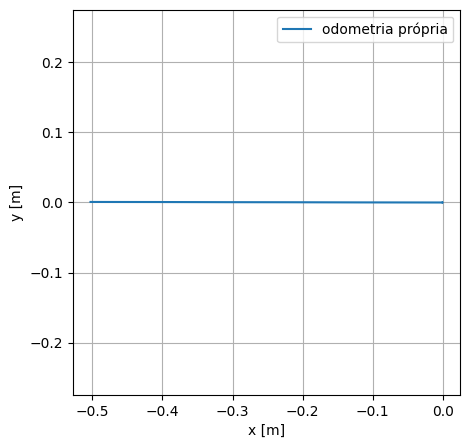

In [7]:
cmd_vel = roslibpy.Topic(client, NS + '/cmd_vel', 'geometry_msgs/Twist')

def move(v, w, duracao, freq=10):
    """Publica (v, w) a 'freq' Hz durante 'duracao' segundos e para."""
    msg = roslibpy.Message({'linear': {'x': v, 'y': 0.0, 'z': 0.0},
                              'angular': {'x': 0.0, 'y': 0.0, 'z': w}})
    t0 = time.time()
    while time.time() - t0 < duracao:
        cmd_vel.publish(msg)
        time.sleep(1.0 / freq)
    cmd_vel.publish(roslibpy.Message({'linear': {'x': 0.0, 'y': 0.0, 'z': 0.0},
                                       'angular': {'x': 0.0, 'y': 0.0, 'z': 0.0}}))
    time.sleep(0.3)

def trajetoria():
    """Trajetória do grupo: EDITE livremente (v em m/s, w em rad/s, duração em s)."""
    move(-0.21, 0.0, 3)    # reta
    move(0.0, 0.4, 3.35)    # giro no lugar
    move(-0.21, 0.0, 3)    # reta

    # move(-0.1, 0.3, 5)    # curva
    # move(-0.1, 0.0, 3)    # reta

# Marca o início do experimento
traj_prop.clear(); traj_odom.clear(); pose_prop[:] = [0.0, 0.0, 0.0]
trajetoria()

P = np.array(traj_prop)
plt.figure(figsize=(5, 5))
plt.plot(P[:, 0], P[:, 1], label='odometria própria')
plt.axis('equal'); plt.grid(True); plt.legend()
plt.xlabel('x [m]'); plt.ylabel('y [m]'); plt.show()


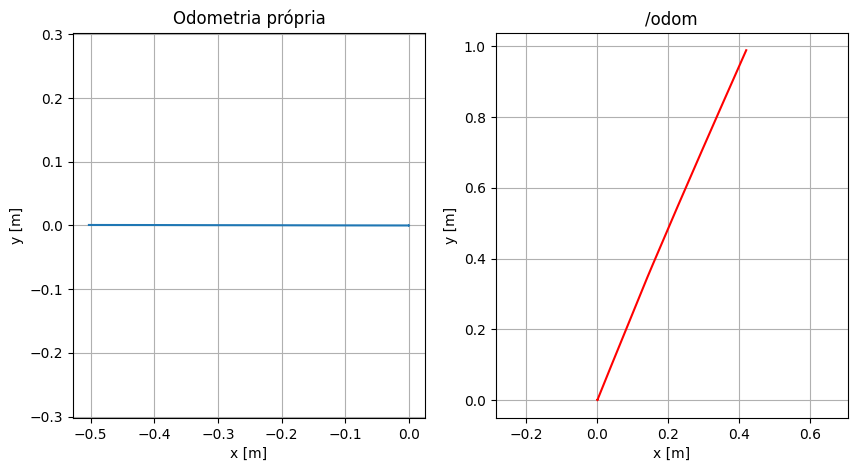

In [8]:
O = np.array(traj_odom)
O = O - O[0]          # começa na origem

fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].plot(P[:, 0], P[:, 1]); ax[0].set_title('Odometria própria')
ax[1].plot(O[:, 0], O[:, 1], 'r'); ax[1].set_title('/odom')
for a in ax:
    a.axis('equal'); a.grid(True); a.set_xlabel('x [m]'); a.set_ylabel('y [m]')
plt.show()


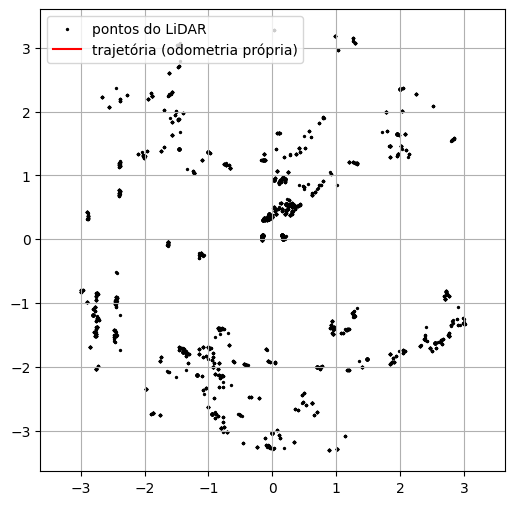

TypeError: Figure.savefig() missing 1 required positional argument: 'fname'

<Figure size 640x480 with 0 Axes>

In [9]:

def mapear(passo=6, freq=20):
    """Roda a trajetória em uma thread e acumula o mapa enquanto o robô anda."""
    nuvem = []
    th = threading.Thread(target=trajetoria)
    th.start()
    while th.is_alive():
        s = ultimo_scan[0]
        if s is not None:
            pts = scan_para_mundo(s['ranges'], s['angle_min'], s['angle_increment'],
                                  tuple(pose_prop), passo=passo)
            nuvem.append(pts)
        time.sleep(1.0 / freq)
    return np.vstack(nuvem)

traj_prop.clear(); pose_prop[:] = [0.0, 0.0, 0.0]
mapa = mapear()

P = np.array(traj_prop)
plt.figure(figsize=(6, 6))
plt.scatter(mapa[:, 0], mapa[:, 1], s=2, c='k', label='pontos do LiDAR')
plt.plot(P[:, 0], P[:, 1], 'r-', label='trajetória (odometria própria)')
plt.axis('equal'); plt.grid(True); plt.legend(); plt.show(); plt.savefig()


## Experimento com gráfico em tempo real (nova célula)

As dez células originais foram preservadas. Esta alternativa mostra os pontos do LiDAR,
a trajetória pela odometria própria e a posição atual enquanto o robô se move.

1. Execute a célula original completa de conexão e callbacks: é a que contém
   `R_RODA = 0.03`, `L_EIXO = 0.28` e as inscrições em `/joint_states`, `/odom` e `/scan`.
   Confira o IP e as medidas do seu robô.
2. Em seguida, execute diretamente a nova célula abaixo para este experimento.
   As células antigas que executam `trajetoria()` e `mapear()` ficam como referência;
   cada uma delas inicia outro percurso se for executada.
3. Para encerrar a conexão, use a célula original de desligamento, logo depois desta.
   Se ela já foi executada, execute novamente a célula de conexão antes de começar.

A sequência `ETAPAS_TEMPO_REAL` reproduz os movimentos originais e pode ser editada.
`freq_plot=5` define uma taxa desejada de até cinco atualizações por segundo; a taxa
real depende da renderização e da chegada dos dados. O movimento envia comandos
separadamente a `freq_cmd=10`. Cada atualização incorpora o scan mais recente ainda
não processado. A pose usada para cada scan é a disponível na coleta, como no código
original; não há sincronização dos sensores por timestamp.

Use **Interromper/Interrupt** para cancelar o percurso e solicitar velocidade zero.
Os dados parciais e a figura final ficam em `mapa_tempo_real`, `P_tempo_real` e
`fig_tempo_real`. As funções antigas `move`, `trajetoria` e `mapear` permanecem intactas.

A figura é atualizada na mesma saída com
[`display_id` do IPython](https://ipython.readthedocs.io/en/stable/api/generated/IPython.display.html#IPython.display.display)
e os pontos são atualizados com
[`set_offsets` do Matplotlib](https://matplotlib.org/stable/api/collections_api.html#matplotlib.collections.PathCollection.set_offsets).


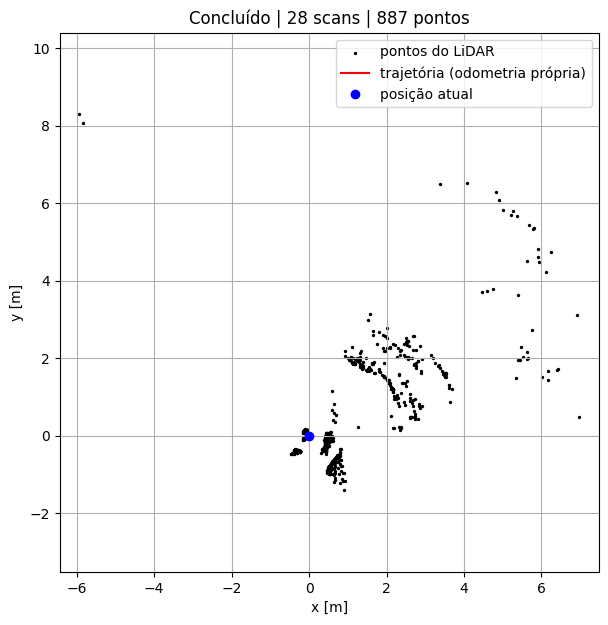

Concluído: 28 scans processados, 887 pontos.


In [15]:
# NOVA CÉLULA: execute depois da conexão e das inscrições nos sensores.
# Use esta célula para o experimento com gráfico ao vivo.
import time
import threading
import numpy as np
import matplotlib.pyplot as plt
import roslibpy
from IPython.display import display
from lab2_utils import scan_para_mundo

# Mesma sequência da trajetória original: (v [m/s], w [rad/s], duração [s]).
ETAPAS_TEMPO_REAL = [
    (-0.25, 0.0, 5.0),
    (0.0, 0.0, 0.0),
    (-0.25, 0.0, 5.0),
]


def mapear_tempo_real(passo=6, freq_plot=5, freq_cmd=10):
    """Move o robô e atualiza trajetória + LiDAR na própria saída da célula."""
    if 'client' not in globals() or not client.is_connected:
        raise RuntimeError('Execute novamente a célula de conexão com os sensores.')
    necessarios = ('NS', 'ultimo_scan', 'traj_prop', 'traj_odom', 'pose_prop',
                  'phi_prev', 'R_RODA', 'L_EIXO')
    if any(nome not in globals() for nome in necessarios):
        raise RuntimeError('Execute a célula completa de conexão e callbacks dos sensores.')
    if R_RODA <= 0 or L_EIXO <= 0:
        raise ValueError('Preencha R_RODA e L_EIXO com as medidas do robô.')
    if ultimo_scan[0] is None or phi_prev[0] is None:
        raise RuntimeError('Sem leituras: confira as inscrições em /joint_states e /scan.')
    if passo < 1 or int(passo) != passo or freq_plot <= 0 or freq_cmd <= 0:
        raise ValueError('Use passo inteiro >= 1 e frequências positivas.')
    passo = int(passo)

    # Um publicador independente; as funções antigas continuam disponíveis.
    comando = roslibpy.Topic(client, NS + '/cmd_vel', 'geometry_msgs/Twist')
    parar = threading.Event()
    erros = []
    nuvem = []
    ultimo_processado = ultimo_scan[0]  # ignora o scan anterior ao experimento
    numero_scans = 0

    def publicar(v=0.0, w=0.0):
        comando.publish(roslibpy.Message({
            'linear': {'x': v, 'y': 0.0, 'z': 0.0},
            'angular': {'x': 0.0, 'y': 0.0, 'z': w},
        }))

    def executar_movimentos():
        # Só esta thread envia movimento; o desenho fica na thread principal.
        try:
            for v, w, duracao in ETAPAS_TEMPO_REAL:
                fim = time.monotonic() + duracao
                while not parar.is_set():
                    restante = fim - time.monotonic()
                    if restante <= 0:
                        break
                    publicar(v, w)
                    if parar.wait(min(1.0 / freq_cmd, restante)):
                        return
                publicar()
                if parar.wait(0.3):  # mesma pausa entre movimentos do código original
                    return
        except Exception as erro:
            erros.append(erro)
        finally:
            try:
                publicar()
            except Exception as erro:
                erros.append(erro)

    def coletar_scan():
        nonlocal ultimo_processado, numero_scans
        s = ultimo_scan[0]
        if s is not None and s is not ultimo_processado:
            ultimo_processado = s
            pontos = scan_para_mundo(
                s['ranges'], s['angle_min'], s['angle_increment'],
                tuple(pose_prop),
                range_min=s.get('range_min', 0.12),
                range_max=s.get('range_max', 3.5),
                passo=passo,
            )
            numero_scans += 1
            if pontos.size:
                nuvem.append(pontos)

    # Cria os elementos gráficos uma vez e atualiza os seus dados no loop.
    with plt.ioff():
        fig, ax = plt.subplots(figsize=(7, 7))
    pontos_lidar = ax.scatter([], [], s=2, c='k', label='pontos do LiDAR')
    linha, = ax.plot([], [], 'r-', label='trajetória (odometria própria)')
    robo, = ax.plot([], [], 'bo', markersize=6, label='posição atual')
    ax.set(xlabel='x [m]', ylabel='y [m]', title='Preparando mapa ao vivo')
    ax.set_aspect('equal', adjustable='box')
    ax.set_xlim(-1, 1)
    ax.set_ylim(-1, 1)
    ax.grid(True)
    ax.legend(loc='upper right')
    saida = display(fig, display_id=True)

    def atualizar_grafico(estado):
        mapa_atual = np.vstack(nuvem) if nuvem else np.empty((0, 2))
        traj_atual = np.asarray(traj_prop[:], dtype=float).reshape(-1, 3)
        x, y, _ = tuple(pose_prop)
        pontos_lidar.set_offsets(mapa_atual)
        linha.set_data(traj_atual[:, 0], traj_atual[:, 1])
        robo.set_data([x], [y])
        # Inclui os pontos do scatter nos limites, mesmo sem trajetória ainda.
        todos = np.vstack((mapa_atual, traj_atual[:, :2], [[0, 0], [x, y]]))
        minimo, maximo = todos.min(axis=0), todos.max(axis=0)
        centro = (minimo + maximo) / 2
        meia_largura = max(maximo - minimo) / 2 + 0.5
        ax.set_xlim(centro[0] - meia_largura, centro[0] + meia_largura)
        ax.set_ylim(centro[1] - meia_largura, centro[1] + meia_largura)
        ax.set_title(f'{estado} | {numero_scans} scans | {len(mapa_atual)} pontos')
        saida.update(fig)  # substitui a figura na mesma saída do notebook
        return mapa_atual, traj_atual

    # Novo experimento: a origem da odometria própria volta a (0, 0, 0).
    traj_prop.clear()
    traj_odom.clear()
    pose_prop[:] = [0.0, 0.0, 0.0]
    phi_prev[0] = None
    trabalhador = threading.Thread(target=executar_movimentos, daemon=True,
                                   name='movimento_tempo_real')
    estado = 'Concluído'
    proximo_plot = 0.0
    try:
        trabalhador.start()
        while trabalhador.is_alive():
            coletar_scan()
            agora = time.monotonic()
            if agora >= proximo_plot:
                atualizar_grafico('Mapeando ao vivo')
                proximo_plot = time.monotonic() + 1.0 / freq_plot
            time.sleep(0.01)
    except KeyboardInterrupt:
        estado = 'Interrompido'
    except Exception:
        estado = 'Erro'
        raise
    finally:
        # Interromper a célula também cancela os próximos movimentos.
        parar.set()
        try:
            if trabalhador.ident is not None:
                trabalhador.join()
        finally:
            try:
                publicar()  # envia zero após a thread parar
                coletar_scan()
                mapa_final, traj_final = atualizar_grafico('Erro' if erros else estado)
            finally:
                plt.close(fig)  # evita uma segunda figura estática ao final da célula

    if erros:
        raise RuntimeError('Falha durante o movimento; parada solicitada.') from erros[0]
    print(f'{estado}: {numero_scans} scans processados, {len(mapa_final)} pontos.')
    return mapa_final, traj_final, fig


# Edite freq_plot para alterar a taxa desejada de atualização do gráfico.
mapa_tempo_real, P_tempo_real, fig_tempo_real = mapear_tempo_real(
    passo=3, freq_plot=5, freq_cmd=10,
)
# Para salvar depois: fig_tempo_real.savefig('mapa_tempo_real.png', dpi=150)


In [34]:
move(0.0, 0.0, 0.2)
t_joint.unsubscribe(); t_odom.unsubscribe(); t_scan.unsubscribe()
client.terminate()


AttributeError: 'TwistedEventLoopManager' object has no attribute '_thread'